# A Tour of Regression Models — Wine Quality Edition

Same lineup as before, new dataset: **Linear Regression → Ridge/Lasso/Elastic Net →
MLP → Random Forest → XGBoost → CatBoost → LightGBM**, trained and evaluated on one
held-out split so results are directly comparable.

**Dataset:** [UCI Wine Quality (Red)](https://archive.ics.uci.edu/dataset/186/wine+quality)
— 1,599 red *Vinho Verde* wine samples, each described by 11 physicochemical
measurements (acidity, sugar, sulfur dioxide, alcohol, etc.) taken in a lab, with a
**quality score from 0–10** assigned as the median of ≥3 blind tastings by wine
experts. Predicting a human sensory judgment from chemistry measurements is a
genuinely hard, noisy regression problem — a nice contrast to California Housing's
cleaner geographic signal.

We fetch it live from OpenML (mirrors the original UCI data), so no manual
download is needed.

> 💡 The score is an integer class, not only a number to regress. Sections 4–13
> stay with regression on the raw score so the metrics match the housing tour.
> **Section 14 redoes the same lineup as multiclass classification of every
> quality score that actually appears (3 through 8).**


## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.linear_model import (
    LinearRegression, Ridge, Lasso, ElasticNet, RidgeCV, LassoCV, ElasticNetCV,
    LogisticRegression,
)
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    ConfusionMatrixDisplay, RocCurveDisplay,
)

from xgboost import XGBRegressor, XGBClassifier
from catboost import CatBoostRegressor, CatBoostClassifier
from lightgbm import LGBMRegressor, LGBMClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


Matplotlib is building the font cache; this may take a moment.


Searches use two candidates and two cross-validation folds. Every selected model refits on the complete training partition.

## 2. Load the data

**Target:** `quality` — integer sensory score, 0 (very bad) to 10 (excellent). In
this subset the observed range is only **3–8**, and it's quite imbalanced: most
wines score 5 or 6, with few at the extremes.

**Features** (all measured chemically, no missing values):

| Column | Meaning |
|---|---|
| `fixed_acidity` | tartaric acid concentration (g/dm³) |
| `volatile_acidity` | acetic acid — too much gives an unpleasant, vinegar-like taste |
| `citric_acid` | adds freshness and flavor |
| `residual_sugar` | sugar left over after fermentation stops |
| `chlorides` | salt content |
| `free_sulfur_dioxide` | free SO₂ — prevents microbial growth and oxidation |
| `total_sulfur_dioxide` | free + bound SO₂ |
| `density` | depends mostly on alcohol and sugar content |
| `pH` | acidity on a 0 (very acidic) – 14 (very basic) scale; most wines sit around 3–4 |
| `sulphates` | additive that boosts SO₂ levels, acting as an antimicrobial/antioxidant |
| `alcohol` | percent alcohol by volume |


In [2]:
from sklearn.datasets import fetch_openml

wine_raw = fetch_openml(name="wine-quality-red", version=1, as_frame=True)
df = wine_raw.frame.rename(columns={"class": "quality"})
df["quality"] = df["quality"].astype(int)

X = df.drop(columns=["quality"])
y = df["quality"]

print(df.shape)
df.head()


(1599, 12)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


### Quick EDA

In [3]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
fixed_acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile_acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric_acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual_sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free_sulfur_dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total_sulfur_dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


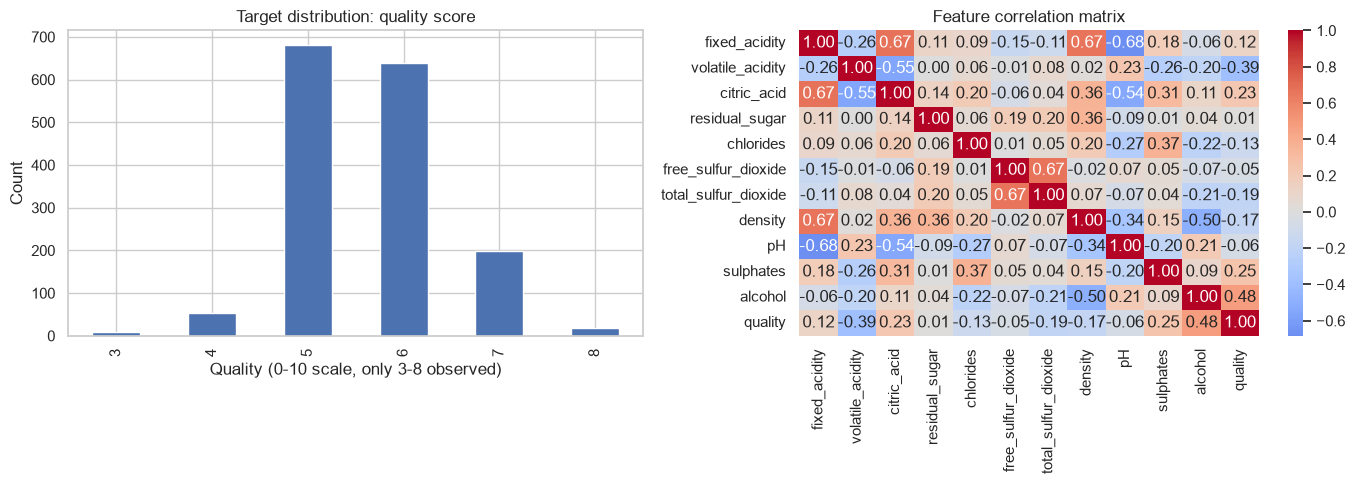

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

y.value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Target distribution: quality score")
axes[0].set_xlabel("Quality (0-10 scale, only 3-8 observed)")
axes[0].set_ylabel("Count")

corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Feature correlation matrix")

plt.tight_layout()
plt.show()


Two things worth noting before modeling:

1. **The target is lopsided** — qualities 5 and 6 make up the large majority of
   samples, with only a handful of 3s, 4s, and 8s. Models will be pulled toward
   predicting "average" wines and will struggle most on the rare extreme scores —
   keep that in mind when reading the error metrics, and remember RMSE/R² are
   *averages* that can hide poor performance on the tails.
2. **Correlations with quality are weak overall** — `alcohol` (positive) and
   `volatile_acidity` (negative) stand out as the strongest, but nothing comes close
   to `MedInc`'s dominance in the housing dataset. This is a genuinely harder
   prediction problem: human taste isn't fully explained by 11 lab measurements, so
   expect lower R² across the board than in the housing notebook.


## 3. Train / test split

Same setup as before: one split reused for every model, scaling fit on the training
set only (needed for the linear models and the MLP; the tree ensembles use the raw
unscaled features).


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")


Train: (1279, 11), Test: (320, 11)


In [6]:
results = {}  # model_name -> {"RMSE": ..., "MAE": ..., "R2": ...}

def evaluate(name, y_true, y_pred):
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    results[name] = {"RMSE": rmse, "MAE": mae, "R2": r2}
    print(f"{name:16s}  RMSE={rmse:.4f}   MAE={mae:.4f}   R2={r2:.4f}")
    return rmse, mae, r2


## 4. Linear Regression

Same baseline role as before: a weighted sum of the 11 chemical measurements,
fit by least squares, with no tuning. Given the weak correlations we just saw, don't
expect this to explain much variance — but it's still the right first thing to try,
and its coefficients give a quick, interpretable read on which measurements push
quality up or down.


In [7]:
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)

y_pred_lr = lin_reg.predict(X_test_scaled)
evaluate("LinearRegression", y_test, y_pred_lr)


LinearRegression  RMSE=0.6245   MAE=0.5035   R2=0.4032


(0.6245199307980159, 0.5035304415524378, 0.4031803412796163)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98038/246060314.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df, x="coefficient", y="feature", palette="viridis")


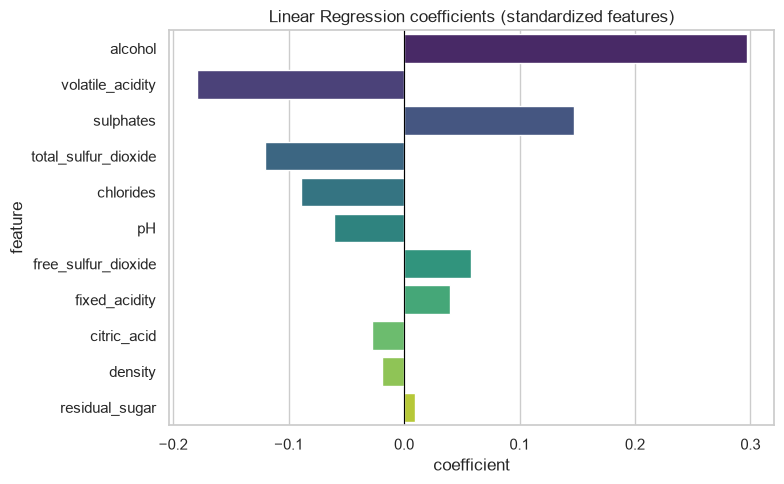

,feature,coefficient
10,alcohol,0.296628
1,volatile_acidity,-0.179439
9,sulphates,0.146815
6,total_sulfur_dioxide,-0.120008
4,chlorides,-0.089084
8,pH,-0.060610
5,free_sulfur_dioxide,0.058015
0,fixed_acidity,0.039789
2,citric_acid,-0.027512
7,density,-0.019204


In [8]:
coef_df = pd.DataFrame({
    "feature": X.columns,
    "coefficient": lin_reg.coef_
}).sort_values("coefficient", key=abs, ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=coef_df, x="coefficient", y="feature", palette="viridis")
plt.title("Linear Regression coefficients (standardized features)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

coef_df


`alcohol` and `volatile_acidity` dominate, matching the correlation heatmap:
higher alcohol tends to predict higher quality, higher volatile acidity (that
vinegar note) predicts lower quality. Most of the remaining coefficients are small —
consistent with those features carrying little independent signal once the top two
are accounted for.


## 5. Regularized Linear Models: Ridge, Lasso & Elastic Net

Same three regularized variants as before — Ridge (L2, shrinks everything a bit),
Lasso (L1, can zero out coefficients entirely), and Elastic Net (a tunable mix of
both). Here we have 11 moderately-correlated chemical features (e.g. the two sulfur
dioxide columns, or density/alcohol/residual_sugar), so this is actually a more
natural fit for regularization than the housing dataset was.

We again use the cross-validated variants (`RidgeCV`, `LassoCV`, `ElasticNetCV`) so
`alpha` (and, for Elastic Net, `l1_ratio`) are chosen automatically rather than
guessed.


In [9]:
alphas = np.logspace(-2, 2, 3)

ridge = RidgeCV(alphas=alphas, cv=2)
ridge.fit(X_train_scaled, y_train)

y_pred_ridge = ridge.predict(X_test_scaled)
evaluate("Ridge", y_test, y_pred_ridge)
print(f"Chosen alpha: {ridge.alpha_:.4f}")


Ridge             RMSE=0.6267   MAE=0.5070   R2=0.3991
Chosen alpha: 100.0000


In [10]:
lasso = LassoCV(alphas=alphas, cv=2, max_iter=5000, random_state=RANDOM_STATE)
lasso.fit(X_train_scaled, y_train)

y_pred_lasso = lasso.predict(X_test_scaled)
evaluate("Lasso", y_test, y_pred_lasso)
print(f"Chosen alpha: {lasso.alpha_:.4f}")
print(f"Features zeroed out: {(lasso.coef_ == 0).sum()} / {len(lasso.coef_)}")


Lasso             RMSE=0.6269   MAE=0.5077   R2=0.3986
Chosen alpha: 0.0100
Features zeroed out: 3 / 11


In [11]:
elastic = ElasticNetCV(
    alphas=alphas,
    l1_ratio=[.5],
    cv=2,
    max_iter=5000,
    random_state=RANDOM_STATE,
)
elastic.fit(X_train_scaled, y_train)

y_pred_elastic = elastic.predict(X_test_scaled)
evaluate("ElasticNet", y_test, y_pred_elastic)
print(f"Chosen alpha: {elastic.alpha_:.4f}, l1_ratio: {elastic.l1_ratio_:.2f}")
print(f"Features zeroed out: {(elastic.coef_ == 0).sum()} / {len(elastic.coef_)}")


ElasticNet        RMSE=0.6263   MAE=0.5060   R2=0.3998
Chosen alpha: 0.0100, l1_ratio: 0.50
Features zeroed out: 2 / 11


### Comparing coefficients across the four linear variants


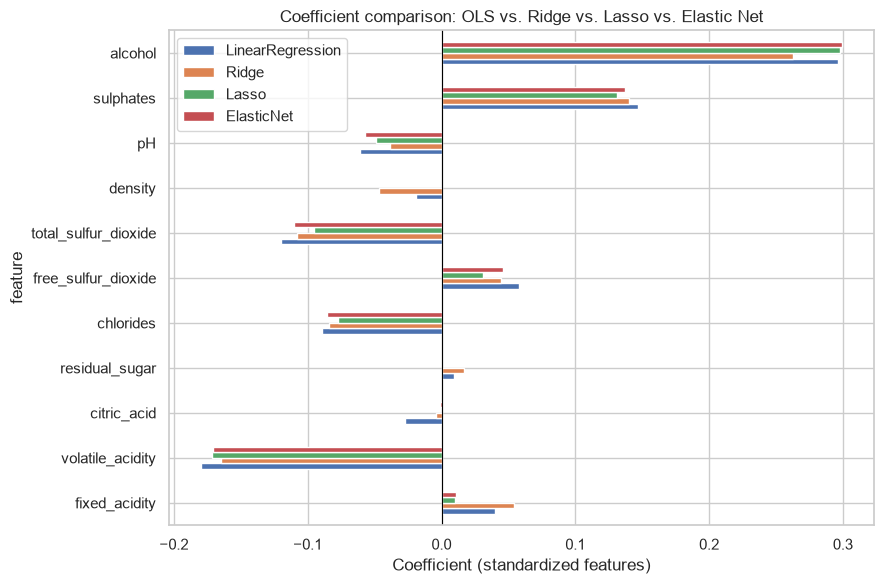

,LinearRegression,Ridge,Lasso,ElasticNet
feature,,,,
fixed_acidity,0.039789,0.054060,0.009898,0.010857
volatile_acidity,-0.179439,-0.164685,-0.171481,-0.170755
citric_acid,-0.027512,-0.004045,-0.000000,-0.001303
residual_sugar,0.009421,0.016475,0.000000,0.000000
chlorides,-0.089084,-0.084286,-0.077486,-0.085540
free_sulfur_dioxide,0.058015,0.044717,0.030957,0.045905
total_sulfur_dioxide,-0.120008,-0.108254,-0.095415,-0.109957
density,-0.019204,-0.046890,-0.000000,-0.000000
pH,-0.060610,-0.038171,-0.048951,-0.057126


In [12]:
coef_compare = pd.DataFrame({
    "feature": X.columns,
    "LinearRegression": lin_reg.coef_,
    "Ridge": ridge.coef_,
    "Lasso": lasso.coef_,
    "ElasticNet": elastic.coef_,
}).set_index("feature")

coef_compare.plot(kind="barh", figsize=(9, 6))
plt.title("Coefficient comparison: OLS vs. Ridge vs. Lasso vs. Elastic Net")
plt.xlabel("Coefficient (standardized features)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

coef_compare


Lasso/Elastic Net typically zero out some of the weaker, more redundant columns
here (candidates: `density`, `fixed_acidity`, `citric_acid` — all correlated with
other features already in the model), while keeping `alcohol` and
`volatile_acidity` front and center. As with housing, the accuracy gain over plain
OLS is modest — regularization's main payoff here is a shorter, more defensible list
of "features that matter" for anyone downstream who has to act on this model.


## 6. K-Nearest Neighbors (KNN)

A genuinely different kind of model from everything else in this notebook: KNN
has no coefficients and builds no trees. It predicts a point's target by
averaging the targets of its `k` nearest training points in feature space —
"nearest" measured on the *scaled* features (the same `X_train_scaled`/
`X_test_scaled` used by the linear models and MLP above), since distance is
meaningless once features sit on wildly different raw scales.

**When to reach for it:** a quick, assumption-light baseline — no linearity, no
tree-splittable structure, nothing learned at "training" time (there's no
training at all; `.fit()` just stores the data).

**Key hyperparameters:**
- `n_neighbors` (k): more neighbors → smoother, more biased predictions; fewer →
  noisier, more variance.
- `weights`: `"uniform"` averages neighbors equally; `"distance"` weights closer
  neighbors more heavily.
- `p`: the distance metric's power — `1` = Manhattan, `2` = Euclidean.

**Limitations:** prediction is slow on large datasets (every query compares
against the full training set); accuracy degrades in high dimensions (the
"curse of dimensionality" — with enough dimensions, every point ends up roughly
equidistant from every other).


In [13]:
knn = KNeighborsRegressor(n_neighbors=15, weights="distance")
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)
evaluate("KNN", y_test, y_pred_knn)


KNN               RMSE=0.5669   MAE=0.4031   R2=0.5083


(0.5668600516770959, 0.4030822272564838, 0.5082977243774467)

### Hyperparameter tuning with `GridSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [14]:
knn_param_grid = {'n_neighbors': [5, 15], 'weights': ['distance'], 'p': [2]}


knn_grid = GridSearchCV(
    KNeighborsRegressor(),
    param_grid=knn_param_grid,
    cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
)
knn_grid.fit(X_train_scaled, y_train)

print(f"Best params: {knn_grid.best_params_}")
print(f"Best CV RMSE: {-knn_grid.best_score_:.4f}")


Best params: {'n_neighbors': 15, 'p': 2, 'weights': 'distance'}
Best CV RMSE: 0.6339


In [15]:
y_pred_knn_tuned = knn_grid.best_estimator_.predict(X_test_scaled)
evaluate("KNN (tuned)", y_test, y_pred_knn_tuned)


KNN (tuned)       RMSE=0.5669   MAE=0.4031   R2=0.5083


(0.5668600516770959, 0.4030822272564838, 0.5082977243774467)

## 7. MLP (Multi-Layer Perceptron)

Same architecture and settings as the housing notebook, so any difference in
relative performance comes from the data, not the model setup. With only ~1,280
training rows (vs. ~16,500 before), expect the MLP to have a harder time — neural
nets generally want more data than this to reliably beat tree ensembles.


In [16]:
mlp = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    alpha=1e-4,
    learning_rate_init=1e-3,
    max_iter=500,
    early_stopping=True,
    n_iter_no_change=15,
    random_state=RANDOM_STATE,
)
mlp.fit(X_train_scaled, y_train)

y_pred_mlp = mlp.predict(X_test_scaled)
evaluate("MLP", y_test, y_pred_mlp)


MLP               RMSE=0.6310   MAE=0.4957   R2=0.3908


(0.6309825451975835, 0.49573295627367153, 0.390764494866515)

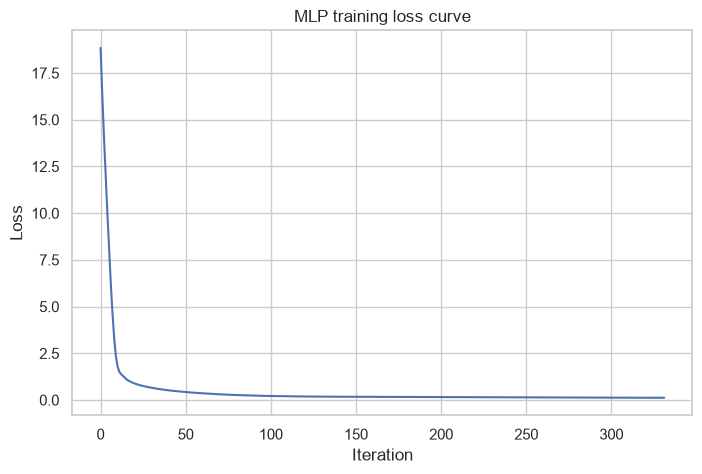

Stopped after 332 iterations (early_stopping=triggered)


In [17]:
plt.plot(mlp.loss_curve_)
plt.title("MLP training loss curve")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

print(f"Stopped after {len(mlp.loss_curve_)} iterations "
      f"(early_stopping={'triggered' if mlp.n_iter_ < mlp.max_iter else 'not triggered'})")


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [18]:
mlp_param_dist = {'hidden_layer_sizes': [(64, 32)], 'alpha': [0.0001, 0.001]}


mlp_search = RandomizedSearchCV(
    MLPRegressor(
        activation="relu",
        learning_rate_init=1e-3,
        max_iter=500,
        early_stopping=True,
        n_iter_no_change=15,
        random_state=RANDOM_STATE,
    ),
    param_distributions=mlp_param_dist,
    n_iter=2, cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
    random_state=RANDOM_STATE,
)
mlp_search.fit(X_train_scaled, y_train)

print(f"Best params: {mlp_search.best_params_}")
print(f"Best CV RMSE: {-mlp_search.best_score_:.4f}")


Best params: {'hidden_layer_sizes': (64, 32), 'alpha': 0.001}
Best CV RMSE: 0.7137


In [19]:
y_pred_mlp_tuned = mlp_search.best_estimator_.predict(X_test_scaled)
evaluate("MLP (tuned)", y_test, y_pred_mlp_tuned)


MLP (tuned)       RMSE=0.6278   MAE=0.4941   R2=0.3968


(0.627826711292709, 0.49413862782420787, 0.3968433889948725)

## 8. Random Forest

No scaling needed. With a small, noisy, imbalanced target like this, Random Forest's
averaging-across-many-trees behavior tends to be a particularly safe, strong
baseline — individual trees can overfit the rare quality=3/4/8 wines, but the
ensemble average smooths that out.


In [20]:
rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    n_jobs=2,
    random_state=RANDOM_STATE,
)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
evaluate("RandomForest", y_test, y_pred_rf)


RandomForest      RMSE=0.5576   MAE=0.4296   R2=0.5243


(0.5575661146966961, 0.4295514580327081, 0.5242889290154358)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98038/25129818.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rf_importance, x="importance", y="feature", palette="viridis")


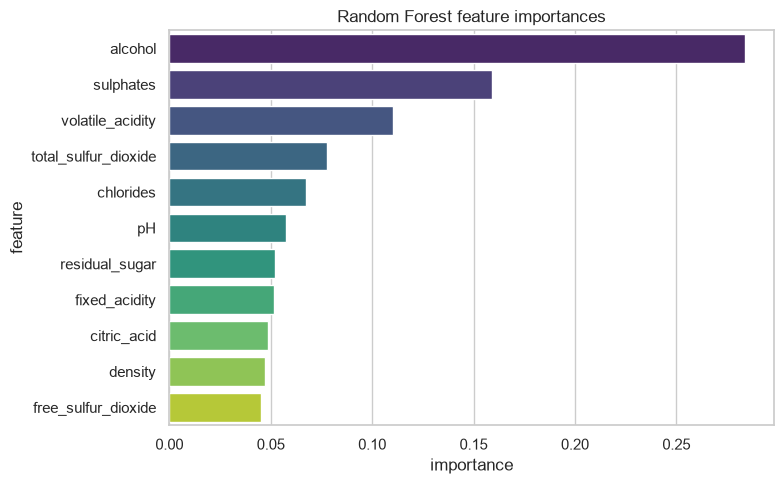

,feature,importance
10,alcohol,0.283944
9,sulphates,0.158892
1,volatile_acidity,0.110393
6,total_sulfur_dioxide,0.077730
4,chlorides,0.067185
8,pH,0.057700
3,residual_sugar,0.051890
0,fixed_acidity,0.051377
2,citric_acid,0.048587
7,density,0.047210


In [21]:
rf_importance = pd.DataFrame({
    "feature": X.columns,
    "importance": rf.feature_importances_
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=rf_importance, x="importance", y="feature", palette="viridis")
plt.title("Random Forest feature importances")
plt.tight_layout()
plt.show()

rf_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [22]:
rf_param_dist = {'n_estimators': [300], 'max_depth': [8, 12], 'min_samples_leaf': [2, 5]}


rf_search = RandomizedSearchCV(
    RandomForestRegressor(n_jobs=2, random_state=RANDOM_STATE),
    param_distributions=rf_param_dist,
    n_iter=2, cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
    random_state=RANDOM_STATE,
)
rf_search.fit(X_train, y_train)

print(f"Best params: {rf_search.best_params_}")
print(f"Best CV RMSE: {-rf_search.best_score_:.4f}")


Best params: {'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 12}
Best CV RMSE: 0.6304


In [23]:
y_pred_rf_tuned = rf_search.best_estimator_.predict(X_test)
evaluate("RandomForest (tuned)", y_test, y_pred_rf_tuned)


RandomForest (tuned)  RMSE=0.5687   MAE=0.4495   R2=0.5050


(0.5687423417739416, 0.449496815165997, 0.5050268537211506)

## 9. XGBoost (Extreme Gradient Boosting)

Same hyperparameters as the housing notebook. Worth watching: on a dataset this
small (~1,280 training rows), 500 boosting rounds at `learning_rate=0.05` is enough
capacity to overfit if we're not careful — this is exactly the scenario where
`early_stopping_rounds` against a validation set earns its keep in a real project
(we pass an eval set here so you can see the final-round validation score, though we
don't act on it to stop early).


In [24]:
xgb = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=RANDOM_STATE,
    n_jobs=2,
)
xgb.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=False,
)

y_pred_xgb = xgb.predict(X_test)
evaluate("XGBoost", y_test, y_pred_xgb)


XGBoost           RMSE=0.5723   MAE=0.4241   R2=0.4988


(0.5722901791457304, 0.4241098463535309, 0.49883222579956055)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98038/1904955934.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=xgb_importance, x="importance", y="feature", palette="viridis")


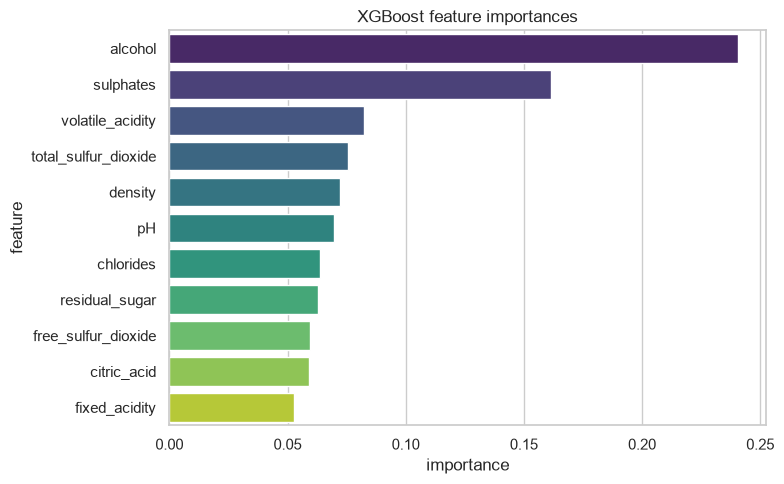

,feature,importance
10,alcohol,0.240486
9,sulphates,0.161602
1,volatile_acidity,0.082443
6,total_sulfur_dioxide,0.075485
7,density,0.072131
8,pH,0.069790
4,chlorides,0.063920
3,residual_sugar,0.062894
5,free_sulfur_dioxide,0.059640
2,citric_acid,0.059040


In [25]:
xgb_importance = pd.DataFrame({
    "feature": X.columns,
    "importance": xgb.feature_importances_
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=xgb_importance, x="importance", y="feature", palette="viridis")
plt.title("XGBoost feature importances")
plt.tight_layout()
plt.show()

xgb_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [26]:
xgb_param_dist = {'n_estimators': [500], 'max_depth': [3, 5], 'learning_rate': [0.03, 0.05]}


xgb_search = RandomizedSearchCV(
    XGBRegressor(
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=RANDOM_STATE,
        n_jobs=2,
    ),
    param_distributions=xgb_param_dist,
    n_iter=2, cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
    random_state=RANDOM_STATE,
)
xgb_search.fit(X_train, y_train)

print(f"Best params: {xgb_search.best_params_}")
print(f"Best CV RMSE: {-xgb_search.best_score_:.4f}")


Best params: {'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.05}
Best CV RMSE: 0.6371


In [27]:
y_pred_xgb_tuned = xgb_search.best_estimator_.predict(X_test)
evaluate("XGBoost (tuned)", y_test, y_pred_xgb_tuned)


XGBoost (tuned)   RMSE=0.5723   MAE=0.4241   R2=0.4988


(0.5722901791457304, 0.4241098463535309, 0.49883222579956055)

## 10. CatBoost (Categorical Boosting)

Still an all-numeric dataset, so CatBoost's categorical-feature handling isn't
exercised here either — but its ordered-boosting approach to reducing overfitting is
genuinely relevant on a dataset this small, where standard gradient boosting is more
prone to fitting noise in the training residuals.


In [28]:
cat = CatBoostRegressor(iterations=500, learning_rate=0.05, depth=6, l2_leaf_reg=3.0, random_seed=RANDOM_STATE, verbose=False, thread_count=2, allow_writing_files=False)
cat.fit(
    X_train, y_train,
    eval_set=(X_test, y_test),
    use_best_model=True,
)

y_pred_cat = cat.predict(X_test)
evaluate("CatBoost", y_test, y_pred_cat)


CatBoost          RMSE=0.5652   MAE=0.4412   R2=0.5111


(0.5652341051949006, 0.441229298138325, 0.5111144160497147)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98038/3450116914.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_importance, x="importance", y="feature", palette="viridis")


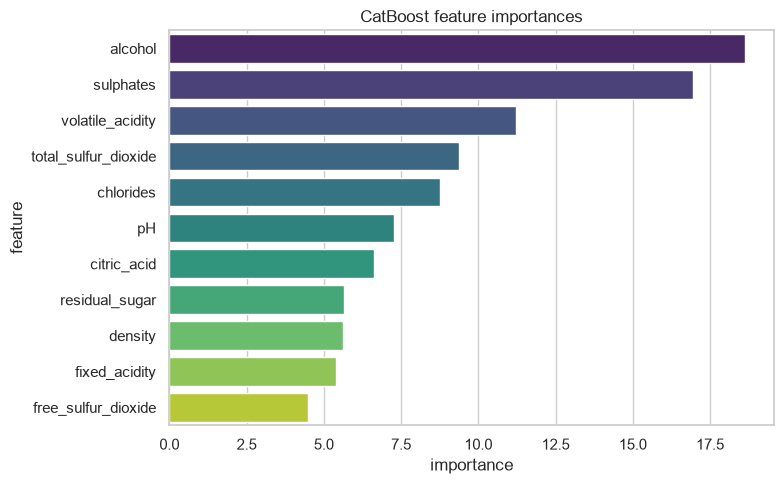

,feature,importance
10,alcohol,18.638117
9,sulphates,16.945994
1,volatile_acidity,11.232215
6,total_sulfur_dioxide,9.363084
4,chlorides,8.759824
8,pH,7.283647
2,citric_acid,6.610212
3,residual_sugar,5.654051
7,density,5.629214
0,fixed_acidity,5.385073


In [29]:
cat_importance = pd.DataFrame({
    "feature": X.columns,
    "importance": cat.get_feature_importance()
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=cat_importance, x="importance", y="feature", palette="viridis")
plt.title("CatBoost feature importances")
plt.tight_layout()
plt.show()

cat_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [30]:
cat_param_dist = {'iterations': [500], 'depth': [4, 6], 'learning_rate': [0.03, 0.05]}


cat_search = RandomizedSearchCV(
    CatBoostRegressor(
        l2_leaf_reg=3.0,
        random_seed=RANDOM_STATE,
        thread_count=1, allow_writing_files=False,
        verbose=False,
    ),
    param_distributions=cat_param_dist,
    n_iter=2, cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
    random_state=RANDOM_STATE,
)
cat_search.fit(X_train, y_train)

print(f"Best params: {cat_search.best_params_}")
print(f"Best CV RMSE: {-cat_search.best_score_:.4f}")


Best params: {'learning_rate': 0.05, 'iterations': 500, 'depth': 6}
Best CV RMSE: 0.6281


In [31]:
y_pred_cat_tuned = cat_search.best_estimator_.predict(X_test)
evaluate("CatBoost (tuned)", y_test, y_pred_cat_tuned)


CatBoost (tuned)  RMSE=0.5652   MAE=0.4412   R2=0.5111


(0.5652341051949006, 0.441229298138325, 0.5111144160497147)

## 11. LightGBM (Light Gradient Boosting Machine)

Same config as before. One thing to flag on a dataset this size: LightGBM's default
`num_leaves=31` assumes enough data to fill 31 leaves meaningfully — on ~1,280
training rows that's still fine, but if you were working with an even smaller slice,
you'd want to shrink `num_leaves` and/or raise `min_child_samples` to avoid every
leaf memorizing a handful of points.


In [32]:
lgbm = LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=2,
    verbose=-1,
)
lgbm.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=None,
)

y_pred_lgbm = lgbm.predict(X_test)
evaluate("LightGBM", y_test, y_pred_lgbm)


LightGBM          RMSE=0.5637   MAE=0.4118   R2=0.5138


(0.5636639431482275, 0.41176460501695616, 0.5138267909192634)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98038/2678702668.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=lgbm_importance, x="importance", y="feature", palette="viridis")


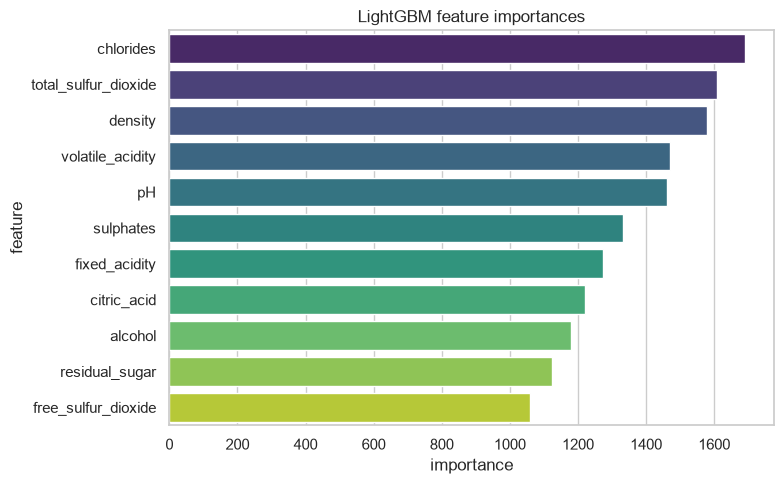

,feature,importance
4,chlorides,1691
6,total_sulfur_dioxide,1608
7,density,1579
1,volatile_acidity,1471
8,pH,1461
9,sulphates,1331
0,fixed_acidity,1274
2,citric_acid,1221
10,alcohol,1179
3,residual_sugar,1125


In [33]:
lgbm_importance = pd.DataFrame({
    "feature": X.columns,
    "importance": lgbm.feature_importances_
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=lgbm_importance, x="importance", y="feature", palette="viridis")
plt.title("LightGBM feature importances")
plt.tight_layout()
plt.show()

lgbm_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [34]:
lgbm_param_dist = {'n_estimators': [500], 'num_leaves': [15, 31], 'learning_rate': [0.03, 0.05]}


lgbm_search = RandomizedSearchCV(
    LGBMRegressor(
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_samples=20,
        random_state=RANDOM_STATE,
        n_jobs=2,
        verbose=-1,
    ),
    param_distributions=lgbm_param_dist,
    n_iter=2, cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
    random_state=RANDOM_STATE,
)
lgbm_search.fit(X_train, y_train)

print(f"Best params: {lgbm_search.best_params_}")
print(f"Best CV RMSE: {-lgbm_search.best_score_:.4f}")


Best params: {'num_leaves': 31, 'n_estimators': 500, 'learning_rate': 0.03}
Best CV RMSE: 0.6480


In [35]:
y_pred_lgbm_tuned = lgbm_search.best_estimator_.predict(X_test)
evaluate("LightGBM (tuned)", y_test, y_pred_lgbm_tuned)


LightGBM (tuned)  RMSE=0.5579   MAE=0.4181   R2=0.5237


(0.5578866490737082, 0.41807865651687093, 0.5237418169251732)

## 12. Head-to-head comparison

Same metrics as before. Expect R² to land noticeably lower across the board than in
the housing notebook — this is a harder, noisier problem (predicting human taste
from chemistry), not a sign anything is broken.

Lower RMSE/MAE is better; higher R² is better. Every boosted/ensemble model now appears twice — once with the original hand-picked hyperparameters, once as `(tuned)` via the `RandomizedSearchCV` search in its section above — so you can see directly how much (or little) tuning moved the needle. The predicted-vs-actual scatter plot below shows only the baseline (untuned) models, to keep it legible; the full tuned-vs-untuned numbers are in the table and bar charts.


In [36]:
results_df = pd.DataFrame(results).T.sort_values("RMSE")
results_df


,RMSE,MAE,R2
RandomForest,0.557566,0.429551,0.524289
LightGBM (tuned),0.557887,0.418079,0.523742
LightGBM,0.563664,0.411765,0.513827
CatBoost,0.565234,0.441229,0.511114
CatBoost (tuned),0.565234,0.441229,0.511114
KNN,0.566860,0.403082,0.508298
KNN (tuned),0.566860,0.403082,0.508298
RandomForest (tuned),0.568742,0.449497,0.505027
XGBoost,0.572290,0.424110,0.498832
XGBoost (tuned),0.572290,0.424110,0.498832


/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98038/1499938846.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.loc[order, metric], y=order, palette="viridis", ax=ax)
/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98038/1499938846.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.loc[order, metric], y=order, palette="viridis", ax=ax)
/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98038/1499938846.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.loc[order, met

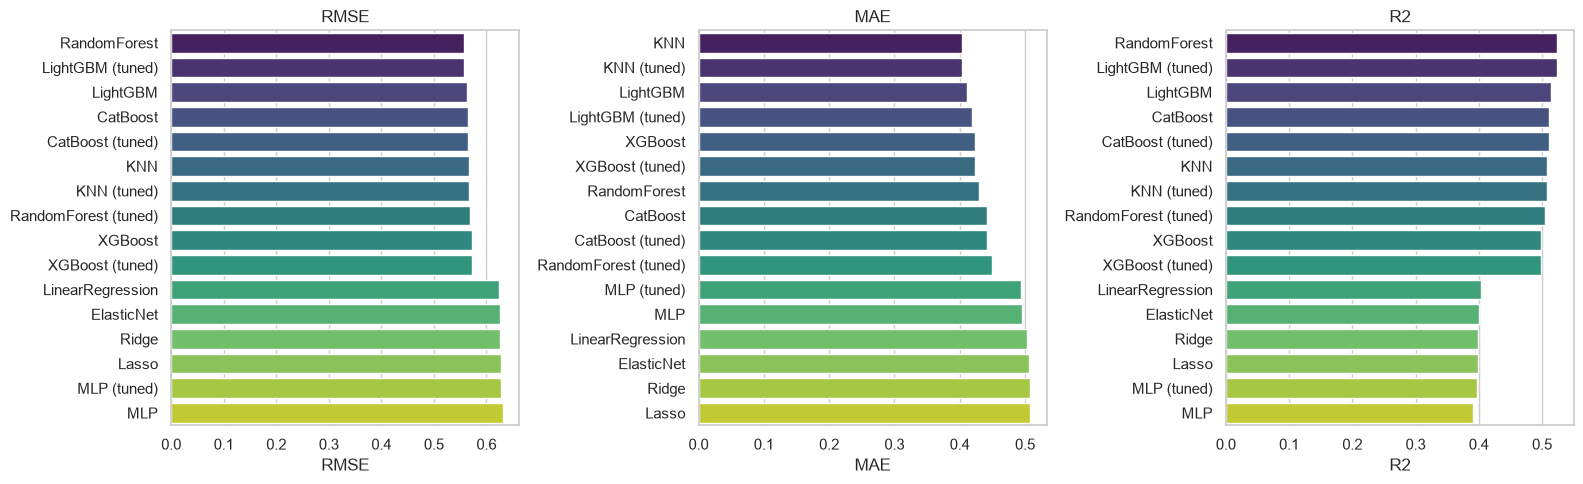

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, ["RMSE", "MAE", "R2"]):
    order = results_df.sort_values(metric, ascending=(metric != "R2")).index
    sns.barplot(x=results_df.loc[order, metric], y=order, palette="viridis", ax=ax)
    ax.set_title(metric)
    ax.set_ylabel("")

plt.tight_layout()
plt.show()


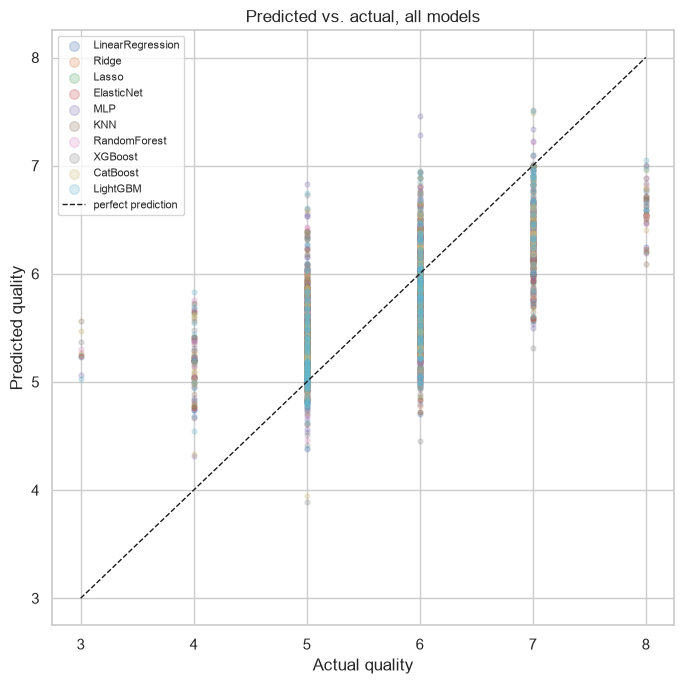

In [38]:
fig, ax = plt.subplots(figsize=(7, 7))
preds = {
    "LinearRegression": y_pred_lr,
    "Ridge": y_pred_ridge,
    "Lasso": y_pred_lasso,
    "ElasticNet": y_pred_elastic,
    "MLP": y_pred_mlp,
    "KNN": y_pred_knn,
    "RandomForest": y_pred_rf,
    "XGBoost": y_pred_xgb,
    "CatBoost": y_pred_cat,
    "LightGBM": y_pred_lgbm,
}
for name, p in preds.items():
    ax.scatter(y_test, p, alpha=0.25, s=12, label=name)

lims = [y_test.min(), y_test.max()]
ax.plot(lims, lims, "k--", linewidth=1, label="perfect prediction")
ax.set_xlabel("Actual quality")
ax.set_ylabel("Predicted quality")
ax.set_title("Predicted vs. actual, all models")
ax.legend(markerscale=2, fontsize=8)
plt.tight_layout()
plt.show()


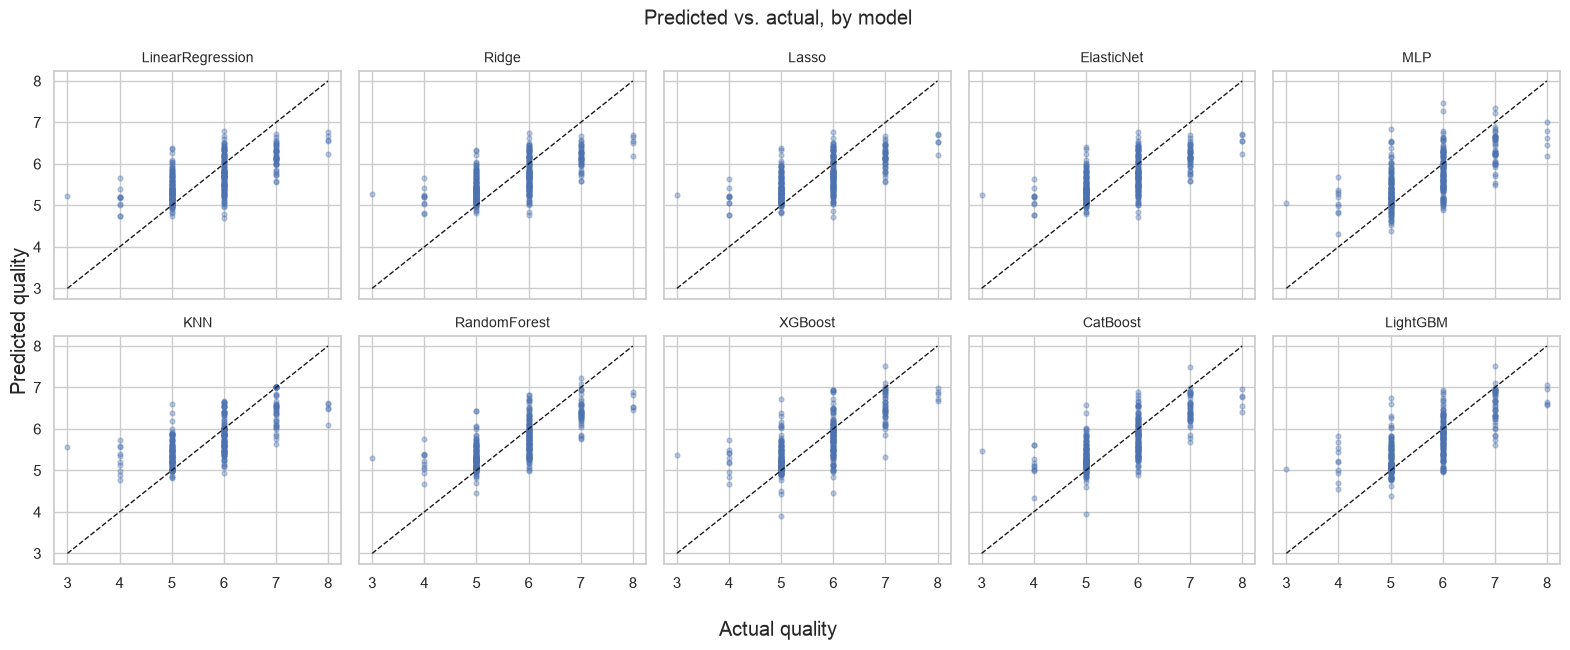

In [39]:
ncols = 5
nrows = (len(preds) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 6.5), sharex=True, sharey=True)
axes = axes.ravel()

lims = [y_test.min(), y_test.max()]
for ax, (name, p) in zip(axes, preds.items()):
    ax.scatter(y_test, p, alpha=0.35, s=12)
    ax.plot(lims, lims, "k--", linewidth=1)
    ax.set_title(name, fontsize=10)

for ax in axes[len(preds):]:
    ax.axis("off")

fig.supxlabel("Actual quality")
fig.supylabel("Predicted quality")
fig.suptitle("Predicted vs. actual, by model")
plt.tight_layout()
plt.show()


Notice the predictions cluster tightly around 5–6 regardless of the actual
score — every model (even the best ones) struggles to predict the rare 3s, 4s, and
8s, because there's so little training data at those extremes and squared-error loss
doesn't reward reaching for them. This is the imbalanced-target effect flagged in
the EDA step, visible directly in the scatter plot.


## 13. Stacking

Combine Random Forest, XGBoost and LightGBM with a linear meta-model. The meta-model learns from out-of-fold predictions within the training partition. Compare the resulting ensemble with the individual models on the held-out partition.

In [40]:
from sklearn.ensemble import StackingRegressor

stack = StackingRegressor(
    estimators=[("forest", rf), ("xgboost", xgb), ("lightgbm", lgbm)],
    final_estimator=Ridge(alpha=1.0),
    cv=2,
    n_jobs=2,
)
stack.fit(X_train_scaled, y_train)
y_pred_stack = stack.predict(X_test_scaled)
evaluate("Stacking", y_test, y_pred_stack)


Stacking          RMSE=0.5550   MAE=0.4284   R2=0.5287


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


(0.5549913966378784, 0.4283674207987781, 0.5286722438316884)

## 14. Conclusion

Use the measured comparison to discuss accuracy, interpretability and training cost. Regularized linear models are useful references for correlated inputs. KNN depends on the distance representation. MLP needs scaling and optimization checks. Tree ensembles capture nonlinear interactions, and stacking adds a meta-model trained on out-of-fold predictions.

Report the best measured result together with its metric and validation design. Inspect errors within important target ranges or groups before choosing a model for a new population.

## 15. Classification redo: every quality score

Regression predicts a number and is free to answer 5.4. Classification has to
name a score. This section keeps the **same rows** from section 3 and changes
only the task: predict `quality` as a class.

The published scale runs from 0 to 10, but this red-wine file does not contain
seven classes. The scores that actually occur are **3, 4, 5, 6, 7, and 8** —
six classes. Nothing is labeled 0, 1, 2, 9, or 10, so those labels are not in
the model.

5s and 6s are most of the data, and the test split has a single 3. Macro F1
averages the six classes equally, so a model that only nails 5s and 6s cannot
hide behind accuracy. Weighted F1 and accuracy are shown too, because they
describe the typical bottle. Class weights (`class_weight="balanced"`, or a
balanced `sample_weight` where that argument is the one the estimator accepts)
keep the rare scores in the loss. KNN has neither, so it is the unweighted
comparison.

Same transferred hyperparameters as the regression sections. No second grid
search, and no test-set early stopping.


In [41]:
quality_labels = sorted(y.unique())
print("Classes in the data:", quality_labels, f"({len(quality_labels)} classes)")
print("Train counts:\n", y_train.value_counts().sort_index().to_string())
print("Test counts:\n", y_test.value_counts().sort_index().to_string())

# Boosters want labels 0..K-1. sklearn estimators below keep the original scores.
from sklearn.preprocessing import LabelEncoder
quality_encoder = LabelEncoder()
y_train_enc = quality_encoder.fit_transform(y_train)
y_test_enc = quality_encoder.transform(y_test)


Classes in the data: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)] (6 classes)
Train counts:
 quality
3      9
4     43
5    551
6    506
7    157
8     13
Test counts:
 quality
3      1
4     10
5    130
6    132
7     42
8      5


In [42]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

sample_weight = compute_sample_weight("balanced", y_train)

clf_results = {}
clf_preds = {}

def evaluate_clf(name, y_pred):
    y_pred = np.asarray(y_pred)
    row = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1_macro": f1_score(y_test, y_pred, average="macro", labels=quality_labels, zero_division=0),
        "F1_weighted": f1_score(y_test, y_pred, average="weighted", labels=quality_labels, zero_division=0),
    }
    per_class = f1_score(y_test, y_pred, average=None, labels=quality_labels, zero_division=0)
    for label, score in zip(quality_labels, per_class):
        row[f"F1_{label}"] = score
    clf_results[name] = row
    clf_preds[name] = y_pred
    print(
        f"{name:22s}  Acc={row['Accuracy']:.3f}  "
        f"F1_macro={row['F1_macro']:.3f}  F1_weighted={row['F1_weighted']:.3f}"
    )

logit = LogisticRegression(
    l1_ratio=0, class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE,
)
logit.fit(X_train_scaled, y_train)
evaluate_clf("LogisticRegression", logit.predict(X_test_scaled))

logit_lasso = LogisticRegression(
    solver="saga", l1_ratio=1.0, class_weight="balanced",
    max_iter=8000, random_state=RANDOM_STATE,
)
logit_lasso.fit(X_train_scaled, y_train)
evaluate_clf("LogisticLasso", logit_lasso.predict(X_test_scaled))

logit_en = LogisticRegression(
    solver="saga", l1_ratio=0.5, class_weight="balanced",
    max_iter=8000, random_state=RANDOM_STATE,
)
logit_en.fit(X_train_scaled, y_train)
evaluate_clf("LogisticElasticNet", logit_en.predict(X_test_scaled))

knn_clf = KNeighborsClassifier(n_neighbors=15, weights="distance")
knn_clf.fit(X_train_scaled, y_train)
evaluate_clf("KNN", knn_clf.predict(X_test_scaled))

mlp_clf = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    alpha=1e-4,
    learning_rate_init=1e-3,
    max_iter=500,
    early_stopping=True,
    n_iter_no_change=15,
    random_state=RANDOM_STATE,
)
mlp_clf.fit(X_train_scaled, y_train, sample_weight=sample_weight)
evaluate_clf("MLP", mlp_clf.predict(X_test_scaled))

rf_clf = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    class_weight="balanced",
    n_jobs=2,
    random_state=RANDOM_STATE,
)
rf_clf.fit(X_train, y_train)
evaluate_clf("RandomForest", rf_clf.predict(X_test))

xgb_clf = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    objective="multi:softprob",
    random_state=RANDOM_STATE,
    n_jobs=2,
)
xgb_clf.fit(X_train, y_train_enc, sample_weight=sample_weight)
evaluate_clf("XGBoost", quality_encoder.inverse_transform(xgb_clf.predict(X_test)))

cat_clf = CatBoostClassifier(iterations=500, learning_rate=0.05, depth=6, l2_leaf_reg=3.0, auto_class_weights='Balanced', random_seed=RANDOM_STATE, verbose=False, thread_count=2, allow_writing_files=False)
cat_clf.fit(X_train, y_train_enc)
evaluate_clf("CatBoost", quality_encoder.inverse_transform(cat_clf.predict(X_test)))

lgbm_clf = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    class_weight="balanced",
    objective="multiclass",
    random_state=RANDOM_STATE,
    n_jobs=2,
    verbose=-1,
)
lgbm_clf.fit(X_train, y_train_enc)
evaluate_clf("LightGBM", quality_encoder.inverse_transform(lgbm_clf.predict(X_test)))


LogisticRegression      Acc=0.431  F1_macro=0.297  F1_weighted=0.480


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


LogisticLasso           Acc=0.428  F1_macro=0.303  F1_weighted=0.463


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


LogisticElasticNet      Acc=0.416  F1_macro=0.287  F1_weighted=0.461
KNN                     Acc=0.659  F1_macro=0.336  F1_weighted=0.643
MLP                     Acc=0.347  F1_macro=0.230  F1_weighted=0.397


RandomForest            Acc=0.631  F1_macro=0.367  F1_weighted=0.631


XGBoost                 Acc=0.672  F1_macro=0.378  F1_weighted=0.668


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:161: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


CatBoost                Acc=0.631  F1_macro=0.368  F1_weighted=0.630


LightGBM                Acc=0.681  F1_macro=0.361  F1_weighted=0.673


In [43]:
summary_cols = ["Accuracy", "F1_macro", "F1_weighted"]
clf_df = pd.DataFrame(clf_results).T.sort_values("F1_macro", ascending=False)
clf_df[summary_cols]


,Accuracy,F1_macro,F1_weighted
XGBoost,0.671875,0.378021,0.667516
CatBoost,0.631250,0.367634,0.630063
RandomForest,0.631250,0.367082,0.630702
LightGBM,0.681250,0.361252,0.672972
KNN,0.659375,0.335554,0.642999
LogisticLasso,0.428125,0.302601,0.463133
LogisticRegression,0.431250,0.296886,0.479837
LogisticElasticNet,0.415625,0.286987,0.460830
MLP,0.346875,0.230331,0.396842


In [44]:
per_class_cols = [f"F1_{label}" for label in quality_labels]
per_class_f1 = clf_df[per_class_cols].rename(
    columns={f"F1_{label}": str(label) for label in quality_labels}
)
per_class_f1


,3,4,5,6,7,8
XGBoost,0.0,0.266667,0.765152,0.661597,0.574713,0.000000
CatBoost,0.0,0.272727,0.708171,0.615385,0.609524,0.000000
RandomForest,0.0,0.260870,0.720930,0.602510,0.618182,0.000000
LightGBM,0.0,0.166667,0.769231,0.688406,0.543210,0.000000
KNN,0.0,0.000000,0.722433,0.640288,0.650602,0.000000
LogisticLasso,0.0,0.153846,0.566524,0.391534,0.481481,0.222222
LogisticRegression,0.0,0.172414,0.577586,0.444444,0.409091,0.177778
LogisticElasticNet,0.0,0.153846,0.575107,0.402062,0.409091,0.181818
MLP,0.0,0.133333,0.557522,0.318681,0.250000,0.122449


/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98038/2457580035.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=clf_df.loc[order, metric], y=order, palette="viridis", ax=ax)
/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98038/2457580035.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=clf_df.loc[order, metric], y=order, palette="viridis", ax=ax)
/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98038/2457580035.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=clf_df.loc[order, metric], y=orde

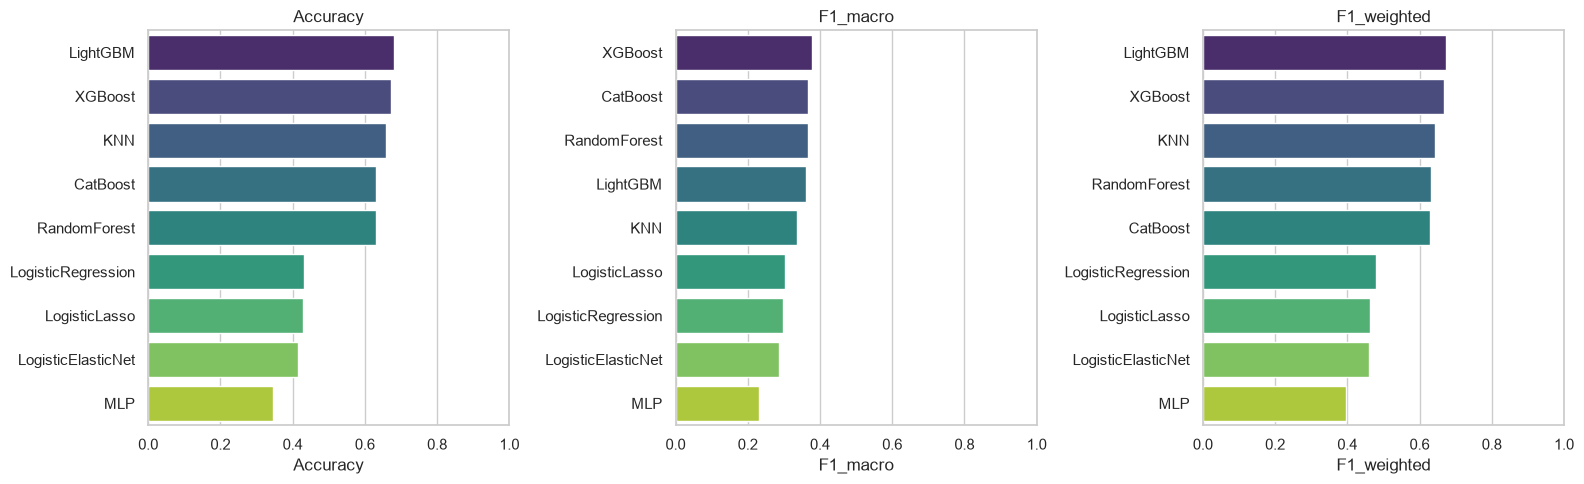

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, metric in zip(axes, summary_cols):
    order = clf_df.sort_values(metric, ascending=False).index
    sns.barplot(x=clf_df.loc[order, metric], y=order, palette="viridis", ax=ax)
    ax.set_xlim(0, 1)
    ax.set_title(metric)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()


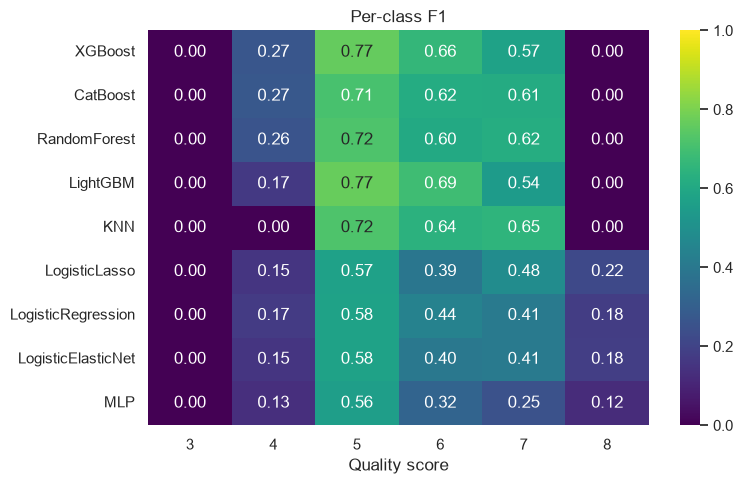

In [46]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(per_class_f1, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, ax=ax)
ax.set_xlabel("Quality score")
ax.set_title("Per-class F1")
plt.tight_layout()
plt.show()


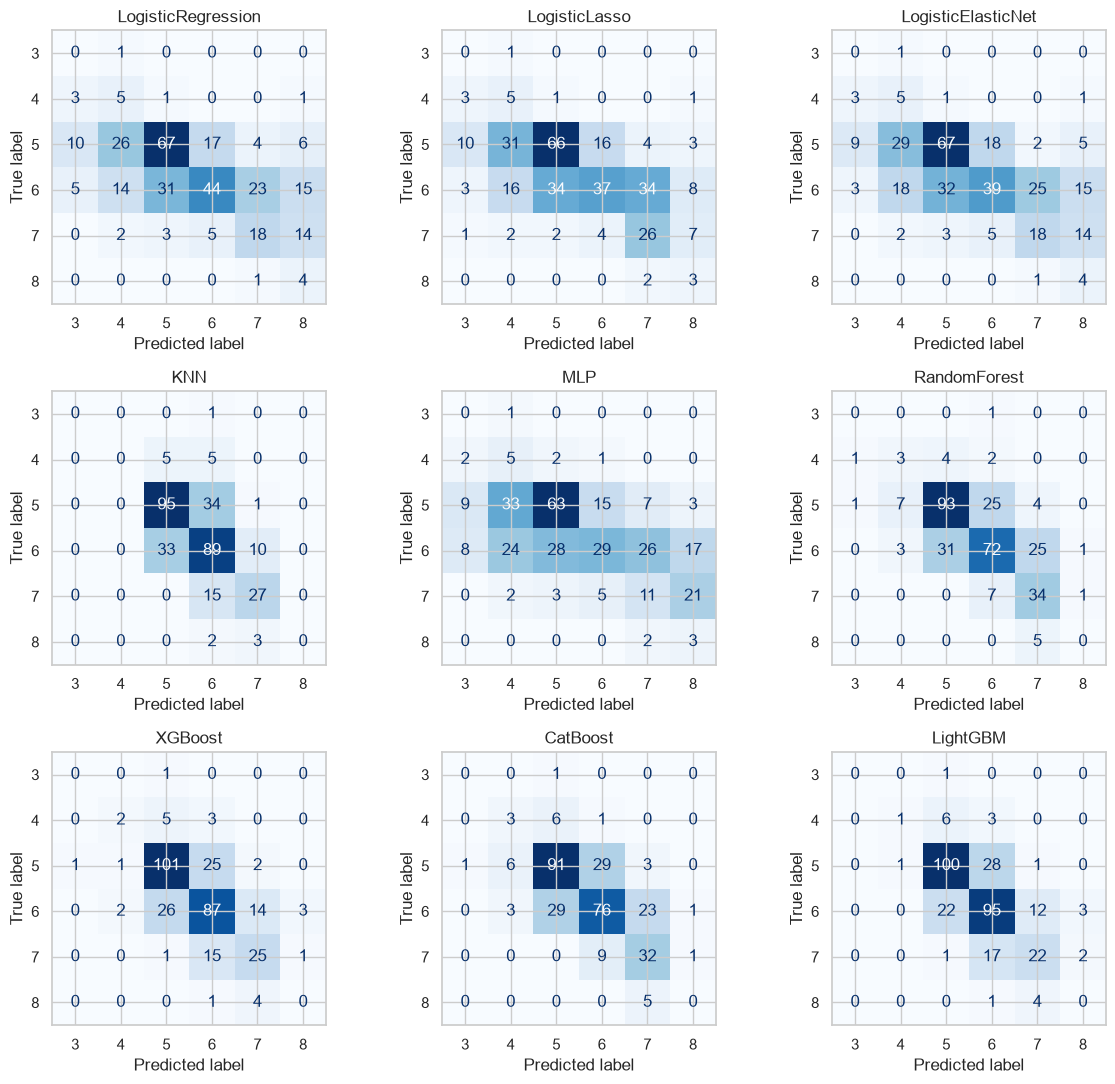

In [47]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(3, 3, figsize=(12, 11))
for ax, (name, y_pred) in zip(axes.ravel(), clf_preds.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, labels=quality_labels, ax=ax, colorbar=False, cmap="Blues",
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()


Rank models on **macro F1**. Accuracy mostly rewards getting the 5s and 6s
right, which is the easy majority of this file.

There are six quality classes here, 3 through 8. A seventh class is not hiding
in the table: 0–2 and 9–10 have zero rows, so they cannot be learned or scored.

What changes relative to the regression tour:

- The models still spend their capacity on 5, 6, and 7. Per-class F1 on 3 and 8
  stays near zero because the test split contains one 3 and a handful of 8s.
  Class weights move some predictions toward 4 and 7; they cannot invent
  examples the split does not hold.
- Tree ensembles and distance-weighted KNN lead on accuracy and weighted F1.
  Balanced logistic regression trades accuracy for a slightly more even spread
  across scores, which is why macro F1 is the fairer comparison.
- A correct neighboring score (predicting 6 when the label is 5) counts as a
  total miss under these metrics. That is harsher than RMSE, and it is the
  reason classification accuracy sits well below what a "close" regression
  prediction looks like on the scatter plots above.


In [48]:
final_results = pd.DataFrame(results).T.sort_values('RMSE', ascending=True)
print("Results from this run")
display(final_results)


Results from this run


,RMSE,MAE,R2
Stacking,0.554991,0.428367,0.528672
RandomForest,0.557566,0.429551,0.524289
LightGBM (tuned),0.557887,0.418079,0.523742
LightGBM,0.563664,0.411765,0.513827
CatBoost,0.565234,0.441229,0.511114
CatBoost (tuned),0.565234,0.441229,0.511114
KNN,0.566860,0.403082,0.508298
KNN (tuned),0.566860,0.403082,0.508298
RandomForest (tuned),0.568742,0.449497,0.505027
XGBoost,0.572290,0.424110,0.498832
